# Simple analysis of historic returns on portfolio including BTCUSDC perp comparison

- In this notebook we analyze historical returns on portfolios with different levels of "risk", trying to replicate the results that Bodie, Kane and Marcus (2024) on its book "Investments" show for this specific section

- Data for T-bills and T-bonds are stracterd from the Kenneth French data library and Damodaran historical return asset

- We also implement the same analysis fro the BTCUSDC perp data, although with limitations regarding to time (the future only has around 2 - 3 years of data)

# 1. Libs

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandas_datareader.data as web
import seaborn as sns
from scipy.stats import norm

from CAPM_model import (
    plot_return_distribution,
    value_at_risk,
    lower_partial_standard_deviation,
    sortino_ratio,
    negative_three_sigma_frequency,
    scenario_analysis,
)
from utils import download_klines, SYMBOL, BASE_URL

# 2. Get data

In [ ]:
ff = web.DataReader(
    "F-F_Research_Data_Factors",
    "famafrench",
    start="1926-07-01",
)
# This data already contains retruns not prices!
annual = ff[1].copy()
annual = annual / 100  # we want decimals
# we are recovering the us market return just by  adding the risk free rate to the market risk free rate returns!
annual["US_Market"] = annual["Mkt-RF"] + annual["RF"]

annual["T_Bills"] = annual["RF"]
returns = annual[["US_Market", "T_Bills"]]
print(returns.head())
print(returns.tail())

# now getting the monthly returns

monthly = ff[0].copy() / 100
excess_returns = monthly["Mkt-RF"]
print(excess_returns.head())
rolling_volatility = excess_returns.rolling(window=12).std(ddof=1)

In [ ]:
# getting BTCUSDC perp data

btcusdcp = download_klines(SYMBOL, "2024-01-31", "2026-11-01")

display(btcusdcp.head())

,date,close
0,2024-01-31 00:00:00+00:00,42532.8
1,2024-02-01 00:00:00+00:00,43054.1
2,2024-02-02 00:00:00+00:00,43163.7
3,2024-02-03 00:00:00+00:00,42984.1
4,2024-02-04 00:00:00+00:00,42548.1


# 3. Following book analysis

## 3.1. Analyzing direct US eturns and comparing with normal distributiosn with their parameters

In [ ]:
# we estimate the riskfree rate from T-bills
risk_free_rate = np.mean(returns["T_Bills"].dropna())
risk_free_rate

np.float64(0.03330808080808081)

,Mean,Standard deviation,Risk Premium,Max,Min
US_Market,0.121935,0.198368,0.088627,0.5679,-0.4377


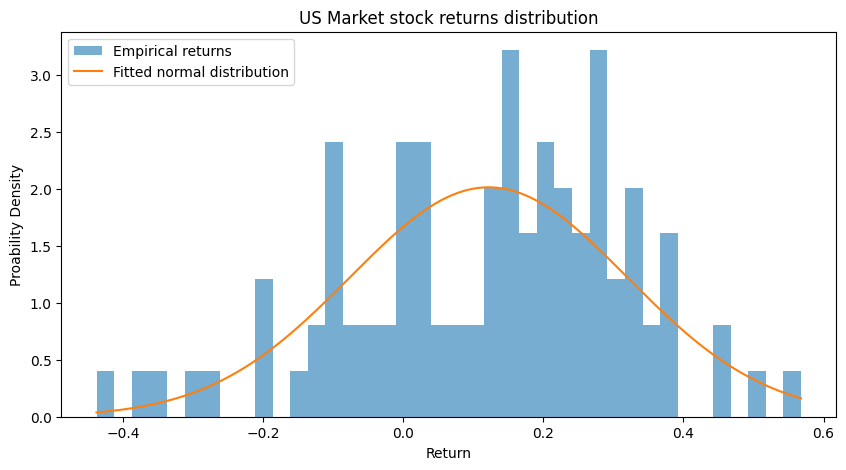

In [ ]:
mean = np.mean(returns["US_Market"].dropna())
std = np.std(returns["US_Market"].dropna(), ddof=1)
risk_premium = mean - risk_free_rate

stats = {
    "Mean": mean,
    "Standard deviation": std,
    "Risk Premium": risk_premium,
    "Max": returns["US_Market"].max(),
    "Min": returns["US_Market"].min(),
}


df = pd.DataFrame(stats, index=["US_Market"])
display(df)

plot_return_distribution(
    returns["US_Market"].dropna(), "US Market stock returns distribution", compare=True
)

,Mean,Standard deviation,Risk Premium,Max,Min
T_Bills,0.033308,0.030579,0.0,0.1471,-0.0002


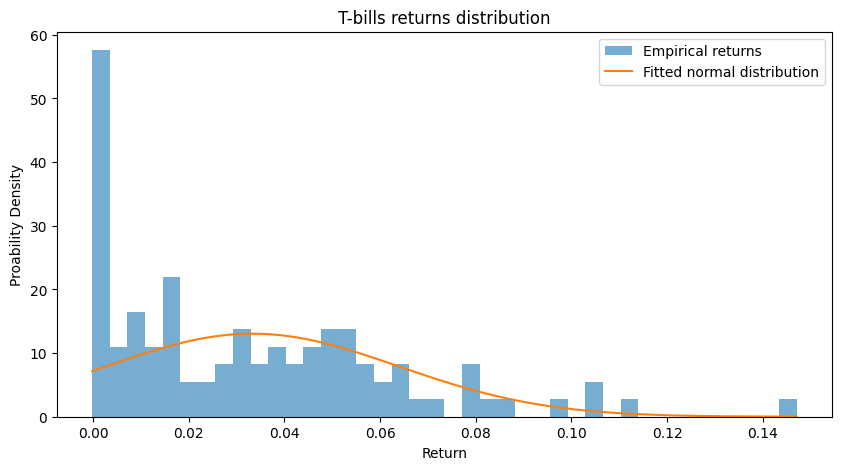

In [ ]:
mean = np.mean(returns["T_Bills"].dropna())
std = np.std(returns["T_Bills"].dropna(), ddof=1)
risk_premium = mean - risk_free_rate

stats = {
    "Mean": mean,
    "Standard deviation": std,
    "Risk Premium": risk_premium,
    "Max": returns["T_Bills"].max(),
    "Min": returns["T_Bills"].min(),
}


df = pd.DataFrame(stats, index=["T_Bills"])
display(df)

plot_return_distribution(
    returns["T_Bills"].dropna(), "T-bills returns distribution", compare=True
)

## 3.2 Now lets use log returns instead

In [ ]:
returns["log_US_Market"] = np.log1p(returns["US_Market"].dropna())
returns["log_T_Bills"] = np.log1p(returns["T_Bills"].dropna())
returns.head()

,US_Market,T_Bills,log_US_Market,log_T_Bills
Date,,,,
1927,0.3256,0.0312,0.281865,0.030723
1928,0.3912,0.0356,0.330167,0.034981
1929,-0.1483,0.0475,-0.160521,0.046406
1930,-0.2873,0.0241,-0.338695,0.023814
1931,-0.4377,0.0107,-0.575720,0.010643


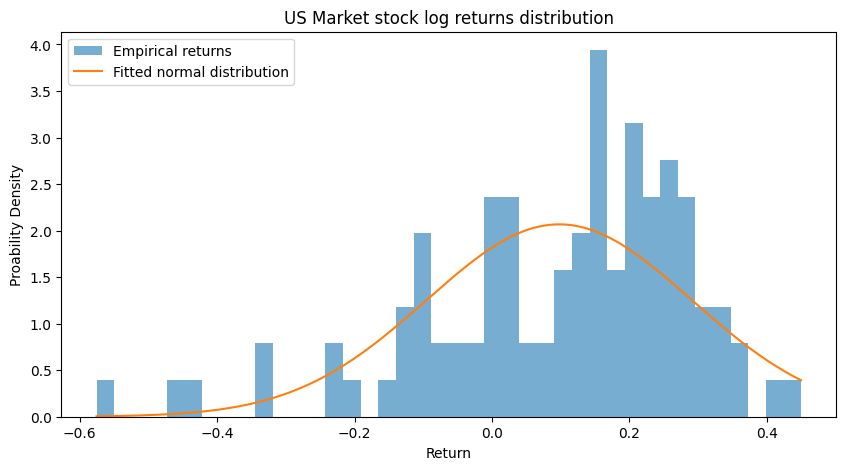

In [ ]:
plot_return_distribution(
    returns["log_US_Market"].dropna(),
    "US Market stock log returns distribution",
    compare=True,
)

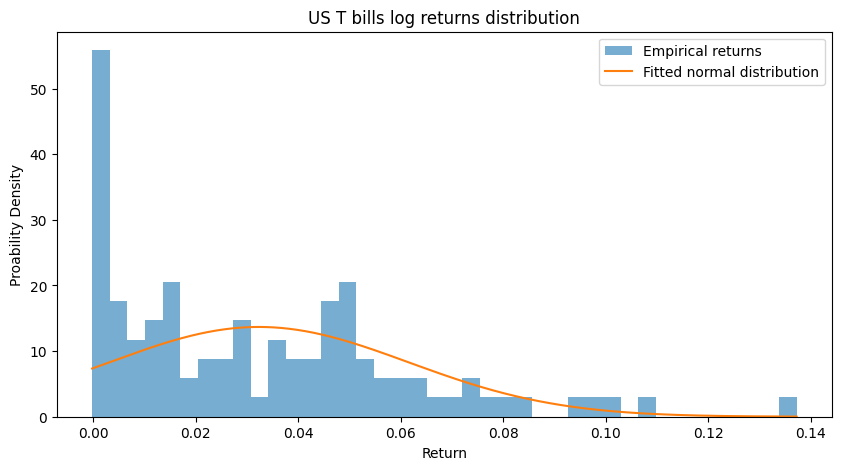

In [ ]:
plot_return_distribution(
    returns["log_T_Bills"].dropna(), "US T bills log returns distribution", compare=True
)

## 3.3 Analyzing monthly excess return on the market index portolio


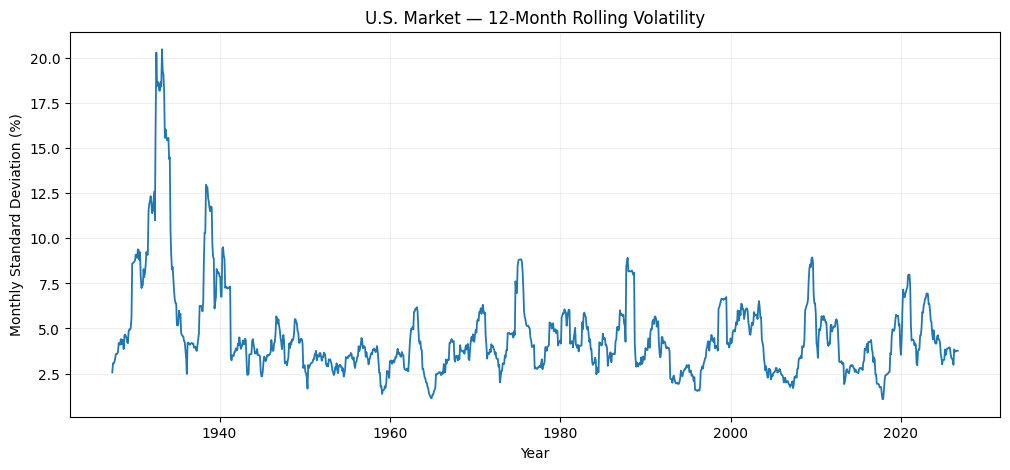

In [ ]:
# 12-month rolling standard deviation of monthly excess returns
rolling_monthly_volatility = excess_returns.rolling(window=12).std(ddof=1)

# Convert monthly volatility to annualized volatility
rolling_annualized_volatility = rolling_monthly_volatility * np.sqrt(12)

rolling_volatility_pct = rolling_volatility * 100

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    rolling_volatility_pct.index.to_timestamp(),
    rolling_volatility_pct,
    linewidth=1.3,
)

ax.set(
    title="U.S. Market — 12-Month Rolling Volatility",
    xlabel="Year",
    ylabel="Monthly Standard Deviation (%)",
)

ax.grid(alpha=0.2)
plt.show()

## 3.4 Frequency distribution of monthly excess returns on the market index versus modeled frequency from a normal distribution with matched mean and standard deviation

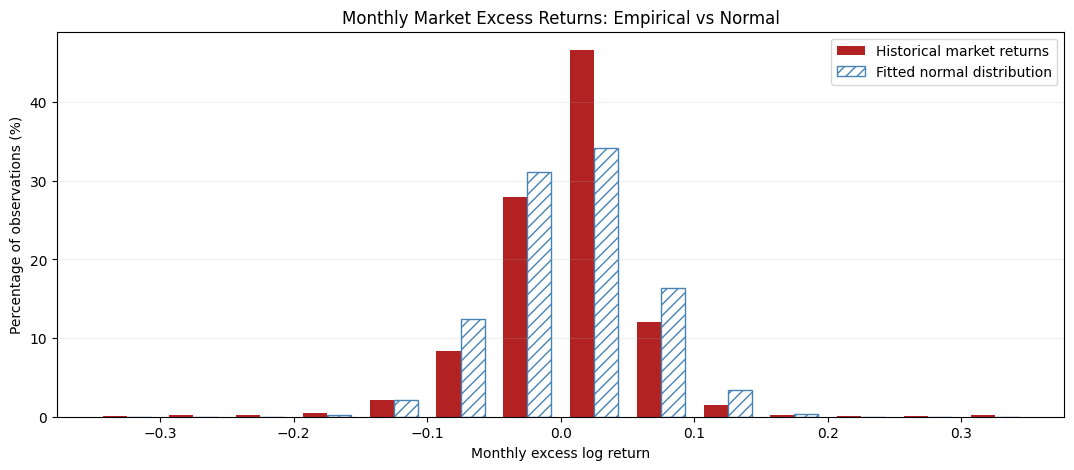

In [ ]:
from scipy.stats import norm

market_simple = monthly["Mkt-RF"] + monthly["RF"]
rf_simple = monthly["RF"]

# Continuously compounded excess return
market_log_excess = (np.log1p(market_simple) - np.log1p(rf_simple)).dropna()

# Estimate normal distribution parameters
mu = market_log_excess.mean()
sigma = market_log_excess.std(ddof=1)
edges = np.arange(-0.35, 0.40, 0.05)

# Empirical frequency per bin
counts, _ = np.histogram(market_log_excess, bins=edges)
empirical_pct = counts / len(market_log_excess) * 100

# Theoretical normal probability per bin
normal_pct = (
    norm.cdf(edges[1:], loc=mu, scale=sigma) - norm.cdf(edges[:-1], loc=mu, scale=sigma)
) * 100

# Plot paired bars
centers = (edges[:-1] + edges[1:]) / 2
bar_width = 0.018

fig, ax = plt.subplots(figsize=(13, 5))

ax.bar(
    centers - bar_width / 2,
    empirical_pct,
    width=bar_width,
    color="firebrick",
    label="Historical market returns",
)

ax.bar(
    centers + bar_width / 2,
    normal_pct,
    width=bar_width,
    facecolor="white",
    edgecolor="steelblue",
    hatch="///",
    label="Fitted normal distribution",
)

ax.set(
    title="Monthly Market Excess Returns: Empirical vs Normal",
    xlabel="Monthly excess log return",
    ylabel="Percentage of observations (%)",
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.show()

# 4. Implementing time series analysis for BTCUSC

In [ ]:
btcusdcp["log_returns"] = np.log(btcusdcp["close"] / btcusdcp["close"].shift(1))
btcusdcp["returns"] = (btcusdcp["close"] / btcusdcp["close"].shift(1)) - 1
btcusdcp = btcusdcp.dropna()
N = len(btcusdcp["log_returns"].dropna())

print(N)
display(btcusdcp.tail())

999


,date,close,log_returns,returns
995,2026-10-22 00:00:00+00:00,81290.0,-0.032749,-0.032218
996,2026-10-23 00:00:00+00:00,81066.6,-0.002752,-0.002748
997,2026-10-24 00:00:00+00:00,80750.0,-0.003913,-0.003905
998,2026-10-25 00:00:00+00:00,80024.0,-0.009031,-0.008991
999,2026-10-26 00:00:00+00:00,80011.2,-0.000160,-0.000160


In [ ]:
0.005005005005005005 / 0.001349898031630093

3.707691164614207

,0
mean,0.0006
simle_returns_mean,0.0009
geometric_mean,0.0006
simle_returns_std,0.0245
std,0.0245
skewness,0.1659
kurtosis,3.6144
sharpe_ratio,0.0343
parametric_VaR,56.2532
non_parametric_VaR,61.1061


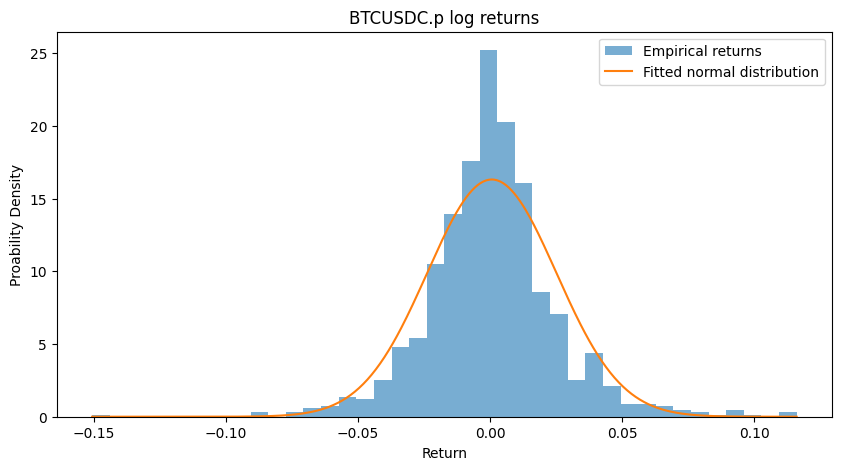

In [ ]:
report = {}

mask = btcusdcp["log_returns"] <= btcusdcp["log_returns"].quantile(0.01)

report["mean"] = btcusdcp["log_returns"].mean()
report["simle_returns_mean"] = btcusdcp["returns"].mean()
report["geometric_mean"] = np.exp(report["mean"]) - 1
report["simle_returns_std"] = btcusdcp["returns"].std()
report["std"] = np.std(btcusdcp["log_returns"], ddof=1)
report["skewness"] = btcusdcp["log_returns"].skew()
report["kurtosis"] = btcusdcp["log_returns"].kurtosis()
report["sharpe_ratio"] = (report["simle_returns_mean"] - daily_risk_free_rate) / report[
    "simle_returns_std"
]
report["parametric_VaR"] = value_at_risk(1000, 0.01, report["mean"], report["std"])[1]
report["non_parametric_VaR"] = btcusdcp["returns"].quantile(0.01) * -1000
report["expected_shortfall"] = btcusdcp[mask]["returns"].mean()
report["lower_partial_std"] = lower_partial_standard_deviation(
    btcusdcp["log_returns"], 0
)
report["negative_three_sigma_frequency"] = negative_three_sigma_frequency(
    btcusdcp["log_returns"]
)

display(pd.DataFrame([report]).T)
plot_return_distribution(btcusdcp["log_returns"], "BTCUSDC.p log returns", compare=True)

In [ ]:
0.0245 / 0.0006

40.833333333333336

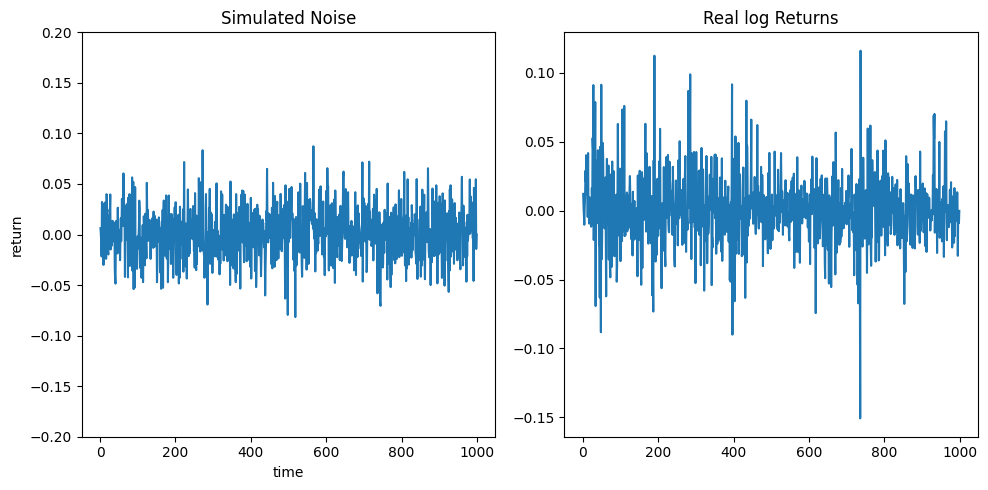

In [ ]:
# simulating a random walk with the btc properties

noise = np.random.normal(loc=report["mean"], scale=report["std"], size=len(btcusdcp))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# Primer gráfico (izquierda)
ax1.plot(btcusdcp.index, noise)
ax1.set_ylim(-0.2, 0.2)
ax1.set_xlabel("time")
ax1.set_ylabel("return")
ax1.set_title("Simulated Noise")


ax2.plot(btcusdcp.index, btcusdcp["log_returns"])
ax2.set_title("Real log Returns")

plt.tight_layout()
plt.show()

In [ ]:
# Chekcing how the distribution changes when we aggregate to montlhy returns
btcusdcp["date"] = pd.to_datetime(btcusdcp["date"], utc=True)

btcusdcp = btcusdcp.set_index("date").sort_index()

monthly_returns = btcusdcp["log_returns"].resample("ME").sum(min_count=1)

monthly_returns.head()

date
2024-02-29 00:00:00+00:00    0.364309
2024-03-31 00:00:00+00:00    0.153339
2024-04-30 00:00:00+00:00   -0.163419
2024-05-31 00:00:00+00:00    0.107799
2024-06-30 00:00:00+00:00   -0.073781
Freq: ME, Name: log_returns, dtype: float64

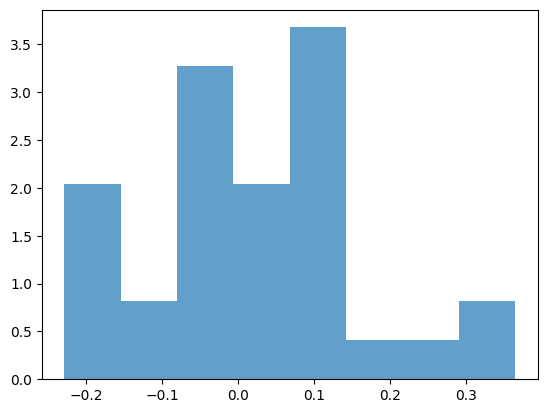

In [ ]:
plt.hist(monthly_returns.dropna(), bins=8, density=True, alpha=0.7)
plt.show()

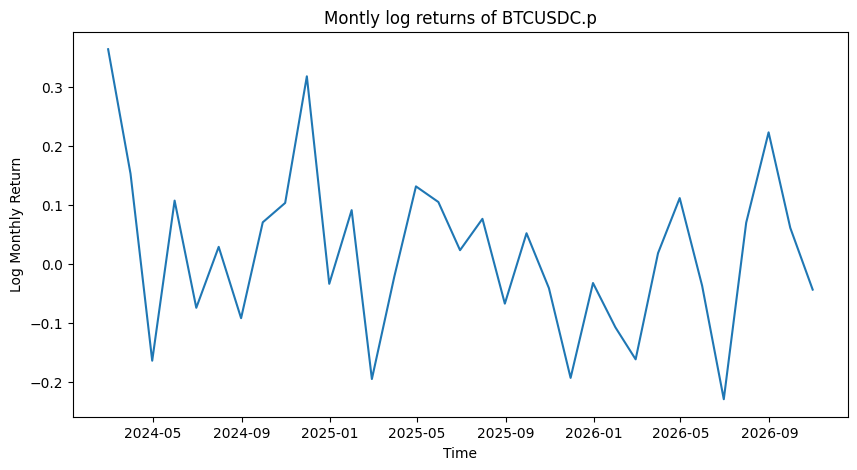

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_returns)
plt.title("Montly log returns of BTCUSDC.p")
plt.ylabel("Log Monthly Return")
plt.xlabel("Time")
plt.show()

# Solving exercises from chapter 5 

11) (Page 192) Visit Professor Kenneth French’s data library Web site, mba.tuck.dartmouth.edu/pages/faculty/
ken.french/data_library.html, and download the monthly returns of “6 portfolios formed on
size and book-to-market (2 × 3).” Choose the value-weighted series for the period from 1927–2021. Split the sample in half and compute the average, SD, skew, and kurtosis for each of the
six portfolios for the two halves. Do the six split-halves statistics suggest to you that returns
come from the same distribution over the entire period?

In [ ]:
import pandas as pd
import numpy as np
from pandas_datareader import data as web
import matplotlib.pyplot as plt
from scipy.stats import norm

dataset = web.DataReader(
    "6_Portfolios_2x3", "famafrench", start="1927-01-01", end="2021-12-31"
)

print(dataset["DESCR"])

6 Portfolios 2x3
----------------

This file was created using the 202609 CRSP database. It contains value- and equal-weighted returns for portfolios formed on ME and BEME. The portfolios are constructed at the end of June. BEME is book value at the last fiscal year end of the prior calendar year divided by ME at the end of December of the prior year. Annual returns are from January to December. Missing data are indicated by -99.99 or -999. The break points include utilities and include financials The portfolios include utilities and include financials. Average Equal Weighted Returns -- Annual Copyright 2026 Eugene F. Fama and Kenneth R. French

  0 : Average Value Weighted Returns -- Monthly (1140 rows x 6 cols)
  1 : Average Equal Weighted Returns -- Monthly (1140 rows x 6 cols)
  2 : Average Value Weighted Returns -- Annual (95 rows x 6 cols)
  3 : (95 rows x 6 cols)
  4 : Number of Firms in Portfolios (1140 rows x 6 cols)
  5 : Average Market Cap (1140 rows x 6 cols)
  6 : For port

In [ ]:
df = dataset[0].copy()

df.columns = [
    "Small/Growth",
    "Small/Neutral",
    "Small/Value",
    "Big/Growth",
    "Big/Neutral",
    "Big/Value",
]

df = df.replace([-99.99, -999], np.nan)

df.head()

,Small/Growth,Small/Neutral,Small/Value,Big/Growth,Big/Neutral,Big/Value
Date,,,,,,
1927-01,-0.8099,-0.3284,3.9875,-0.2624,0.0374,4.4694
1927-02,3.9809,6.1106,6.4416,5.0212,3.5751,8.6332
1927-03,-2.2271,-1.6348,-3.1144,1.2856,0.2316,-2.4761
1927-04,-1.3839,1.2648,3.4837,3.0757,-0.7725,-0.5495
1927-05,5.4624,3.5551,13.4556,5.4126,5.0911,7.4919


In [ ]:
midpoint = len(df) // 2

first_half = df.iloc[:midpoint]
second_half = df.iloc[midpoint:]

print("First half:")
print(first_half.index.min(), first_half.index.max())

print("second half:")
print(second_half.index.min(), second_half.index.max())

First half:
1927-01 1974-06
second half:
1974-07 2021-12


In [ ]:
fh_stats = first_half.agg(["mean", "std", "skew", "kurt"])
sh_stats = second_half.agg(["mean", "std", "skew", "kurt"])

display(fh_stats)
display(sh_stats)

,Small/Growth,Small/Neutral,Small/Value,Big/Growth,Big/Neutral,Big/Value
mean,0.927178,1.138921,1.439762,0.826360,0.855574,1.212962
std,8.140680,8.294227,10.032232,5.788761,6.661459,8.735673
skew,1.101094,1.536082,2.252194,0.015389,1.638767,1.751415
kurt,9.076394,12.920353,17.411354,6.598892,17.309684,14.891004


,Small/Growth,Small/Neutral,Small/Value,Big/Growth,Big/Neutral,Big/Value
mean,1.082018,1.385729,1.450657,1.070627,1.079154,1.184225
std,6.757077,5.382495,5.712288,4.727406,4.433693,5.113508
skew,-0.341347,-0.565734,-0.576935,-0.312971,-0.514730,-0.668128
kurt,2.142673,3.471837,4.530533,1.862962,2.759566,3.714966


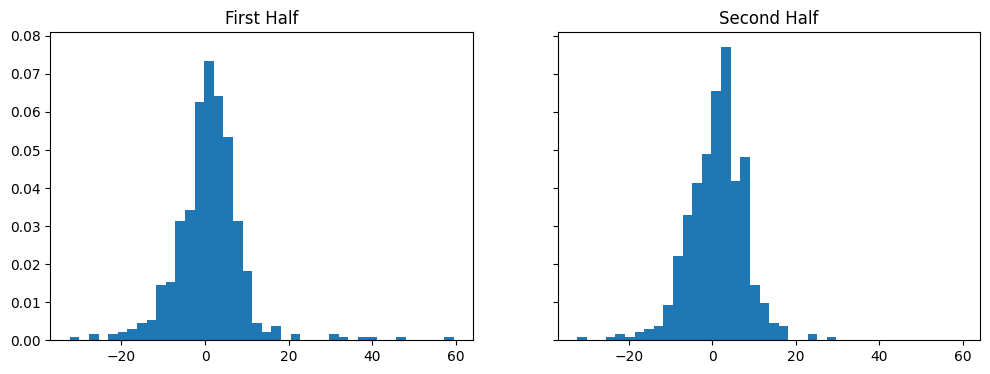

In [ ]:
col = "Small/Growth"

bins = np.histogram_bin_edges(df[col].dropna(), bins=40)

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)

ax[0].hist(first_half[col], bins=bins, density=True)
ax[1].hist(second_half[col], bins=bins, density=True)

ax[0].set_title("First Half")
ax[1].set_title("Second Half")

plt.show()

16) You are faced with the probability distribution of the HPR on the stock market index fund given
in Spreadsheet 5.1 of the text. Suppose the price of a put option on a share of the index fund
with exercise price of $110 and time to expiration of 1 year is $12.
a. What is the probability distribution of the HPR on the put option?
b. What is the probability distribution of the HPR on a portfolio consisting of one share of the
index fund and a put option?
c. In what sense does buying the put option constitute a purchase of insurance in this case?

In [12]:
probs = np.array([0.25, 0.45, 0.25, 0.05])
hprs = np.array([0.31, 0.14, -0.0675, -0.52])

purchase_price = 100
end_prices = purchase_price * (1.0 + hprs)

# put option

premium = 12
strike_price = 110
put_hpr_distrib = (np.maximum(strike_price - end_prices, 0) - premium) / premium
expected_put = np.dot(probs, put_hpr_distrib)
# portfolio of 1 share of the index fund and a put option

portfolio_dist = (end_prices + np.maximum(strike_price - end_prices, 0)) / (
    purchase_price + premium
) - 1
expected_portfolio = np.dot(probs, portfolio_dist)
expected_return = np.dot(probs, hprs)
print(expected_return, expected_put, expected_portfolio)

0.09762500000000002 -0.3927083333333333 0.04508928571428579


17) Suppose the risk-free interest rate is 6% per year. You are contemplating investing $107.55 in
a 1-year CD and simultaneously buying a call option on the stock market index fund with an
exercise price of $110 and expiration of 1 year. Using the scenario analysis of Spreadsheet 5.1,
what is the probability distribution of your dollar return at the end of the year?

In [13]:
risk_free_rate = 0.06
investment = 107.55

final_investment = investment * (1 + risk_free_rate)

# call option

strike_price = 110
premium = 8.23
call_hpr_distrib = (np.maximum(end_prices - strike_price, 0) - premium) / (1)
print(end_prices)


# portfolio

portfolio_return = (final_investment + np.maximum(end_prices - strike_price, 0)) - (
    premium + investment
)
portfolio_return

[131.   114.    93.25  48.  ]


array([19.223,  2.223, -1.777, -1.777])

In [14]:
# simple version
q_rate = 0.02
q_sd = 0.1

annual_log_rate = 4 * np.log1p(q_rate)
annual_log_sd = q_sd * np.sqrt(4)

print(annual_log_rate, annual_log_sd)

# real risk free continously compounded return

bond_price = 84.49
face_value = 100
maturity = 10
inflation = 0.03

real_rf_ear = (face_value / bond_price) ** (1 / maturity) - 1
real_rf_log = np.log1p(real_rf_ear)


log_inflation = np.log1p(inflation)

risk_premium = annual_log_rate - log_inflation - real_rf_log

print(f"Annual nominal log rate: {annual_log_rate:.3%}")
print(f"Annual log inflation: {log_inflation:.3%}")
print(f"Real risk-free log rate: {real_rf_log:.3%}")
print(f"Real risk premium: {risk_premium:.3%}")

0.07921050918471885 0.2
Annual nominal log rate: 7.921%
Annual log inflation: 2.956%
Real risk-free log rate: 1.685%
Real risk premium: 3.280%


In [15]:
# Quantitative approach: The problem is when we thake expectations, the Jensen's inequality bias the estimation!
# since we don't have the entire probability distributon of quarterly returns, we cannot calculate the exact
# expected log return   , so we will try to approximate! u_log = u - sigma^2/2
q_log_sd = (q_sd / (1 + q_rate)) * np.sqrt(4)
aprox_log_mean = (q_rate - 0.5 * ((q_rate**2) + (q_sd) ** 2)) * 4

print(
    f"annual log rate: {annual_log_rate:.3%} vs \n approx log rate: {aprox_log_mean:.3%}"
)
print(f"annual log std: {annual_log_sd:.2%} vs \napprox log std: {q_log_sd:.2%}")
aprox_risk_premium = aprox_log_mean - log_inflation - real_rf_log

print(f"More pricse Real Risk premium of the investment: {aprox_risk_premium:.2%}")

annual log rate: 7.921% vs 
 approx log rate: 5.920%
annual log std: 20.00% vs 
approx log std: 19.61%
More pricse Real Risk premium of the investment: 1.28%


In [16]:
# c) c. What is the probability of loss on the real estate investment after 10 years?

# first we calculate the distrubtion of 10 years:

d_log_rate = 10 * aprox_log_mean
d_log_sd = np.sqrt(10) * q_log_sd

Z = (0 - d_log_rate) / d_log_sd
prob_loss = norm.cdf(Z)
print(f"10-year log mean: {d_log_rate:.3%}")
print(f"10-year log SD: {d_log_sd:.3%}")
print(f"Z-score: {Z:.4f}")
print(f"Probability of loss: {prob_loss:.3%}")

10-year log mean: 59.200%
10-year log SD: 62.005%
Z-score: -0.9548
Probability of loss: 16.985%


In [2]:
capital = 10000
p = np.array([0.2, 0.5, 0.3])
r_x = np.array([-0.2, 0.18, 0.5])
r_y = np.array([-0.15, 0.2, 0.1])


expected_mean_x = np.dot(r_x, p)
expected_mean_y = np.dot(r_y, p)

print(expected_mean_x, expected_mean_y)

0.19999999999999998 0.1


In [8]:
X = scenario_analysis(p, r_x, 0, 0, 9000)

Y = scenario_analysis(p, r_y, 0, 0, 1000)

(X["Expected_return"] + 1) * 9000 + 1000 * (Y["Expected_return"] + 1)

np.float64(11900.0)

{'HPR': array([-0.15,  0.2 ,  0.1 ]),
 'Expected_return': np.float64(0.1),
 'Variance_HPR': np.float64(0.0175),
 'Risk': np.float64(0.13228756555322954),
 'Risk_premium': np.float64(0.1),
 'Expected_value': np.float64(1100.0)}